# Evaluasi Kinerja Decision Tree, Random Forest, XGBoost, dan LightGBM dengan Penanganan Imbalanced Data Menggunakan SMOTE pada Prediksi Penyakit Diabetes

**Alur:** 1) Import & Konfigurasi → 2) Load Data → 3) EDA → 4) Preprocessing → 5) Split 80:20 → 6) SMOTE → 7) Tanpa SMOTE vs Dengan SMOTE → 8) 10-Fold CV → 9) Evaluasi Semua Fitur → 10) Feature Importance & Reduksi Fitur

## 1. Import Module & Konfigurasi

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_style('whitegrid')

# ================== KONFIGURASI (BISA DIUBAH) ==================
CSV_PATH         = 'diabetes_prediction_dataset.csv'  # lokasi file dataset
RANDOM_STATE     = 42
TEST_SIZE        = 0.20   # split 80:20
N_FOLDS          = 10     # jumlah fold cross-validation
N_DROP_FEATURES  = 0      # JUMLAH FITUR TERBAWAH YANG DIBUANG saat reduksi fitur (dari 8 fitur)
# ================================================================

## 2. Load Data

In [2]:
df = pd.read_csv(CSV_PATH)
print('Ukuran data awal :', df.shape)
df.head()

Ukuran data awal : (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0000,0,1,never,25.1900,6.6000,140,0
1,Female,54.0000,0,0,No Info,27.3200,6.6000,80,0
2,Male,28.0000,0,0,never,27.3200,5.7000,158,0
3,Female,36.0000,0,0,current,23.4500,5.0000,155,0
4,Male,76.0000,1,1,current,20.1400,4.8000,155,0


## 3. Exploratory Data Analysis (EDA) data mentah

### 3.1 Statistik Deskriptif

In [3]:
num_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

# Statistik fitur numerik: Min, Maks, Mean, Median, Std
desc = df[num_cols].agg(['min', 'max', 'mean', 'median', 'std']).T
desc.columns = ['Min', 'Maks', 'Mean', 'Median', 'Std. Dev.']
display(desc)

# Frekuensi kategori
for c in ['gender', 'smoking_history']:
    f = df[c].value_counts().to_frame('Frekuensi')
    f['Persen (%)'] = f['Frekuensi'] / len(df) * 100
    print(f'\nFrekuensi {c}'); display(f)

,Min,Maks,Mean,Median,Std. Dev.
age,0.0800,80.0000,41.8859,43.0000,22.5168
bmi,10.0100,95.6900,27.3208,27.3200,6.6368
HbA1c_level,3.5000,9.0000,5.5275,5.8000,1.0707
blood_glucose_level,80.0000,300.0000,138.0581,140.0000,40.7081



Frekuensi gender


,Frekuensi,Persen (%)
gender,,
Female,58552,58.5520
Male,41430,41.4300
Other,18,0.0180



Frekuensi smoking_history


,Frekuensi,Persen (%)
smoking_history,,
No Info,35816,35.8160
never,35095,35.0950
former,9352,9.3520
current,9286,9.2860
not current,6447,6.4470
ever,4004,4.0040


### 3.2 Distribusi Fitur (Histogram + KDE) dan Boxplot per Kelas

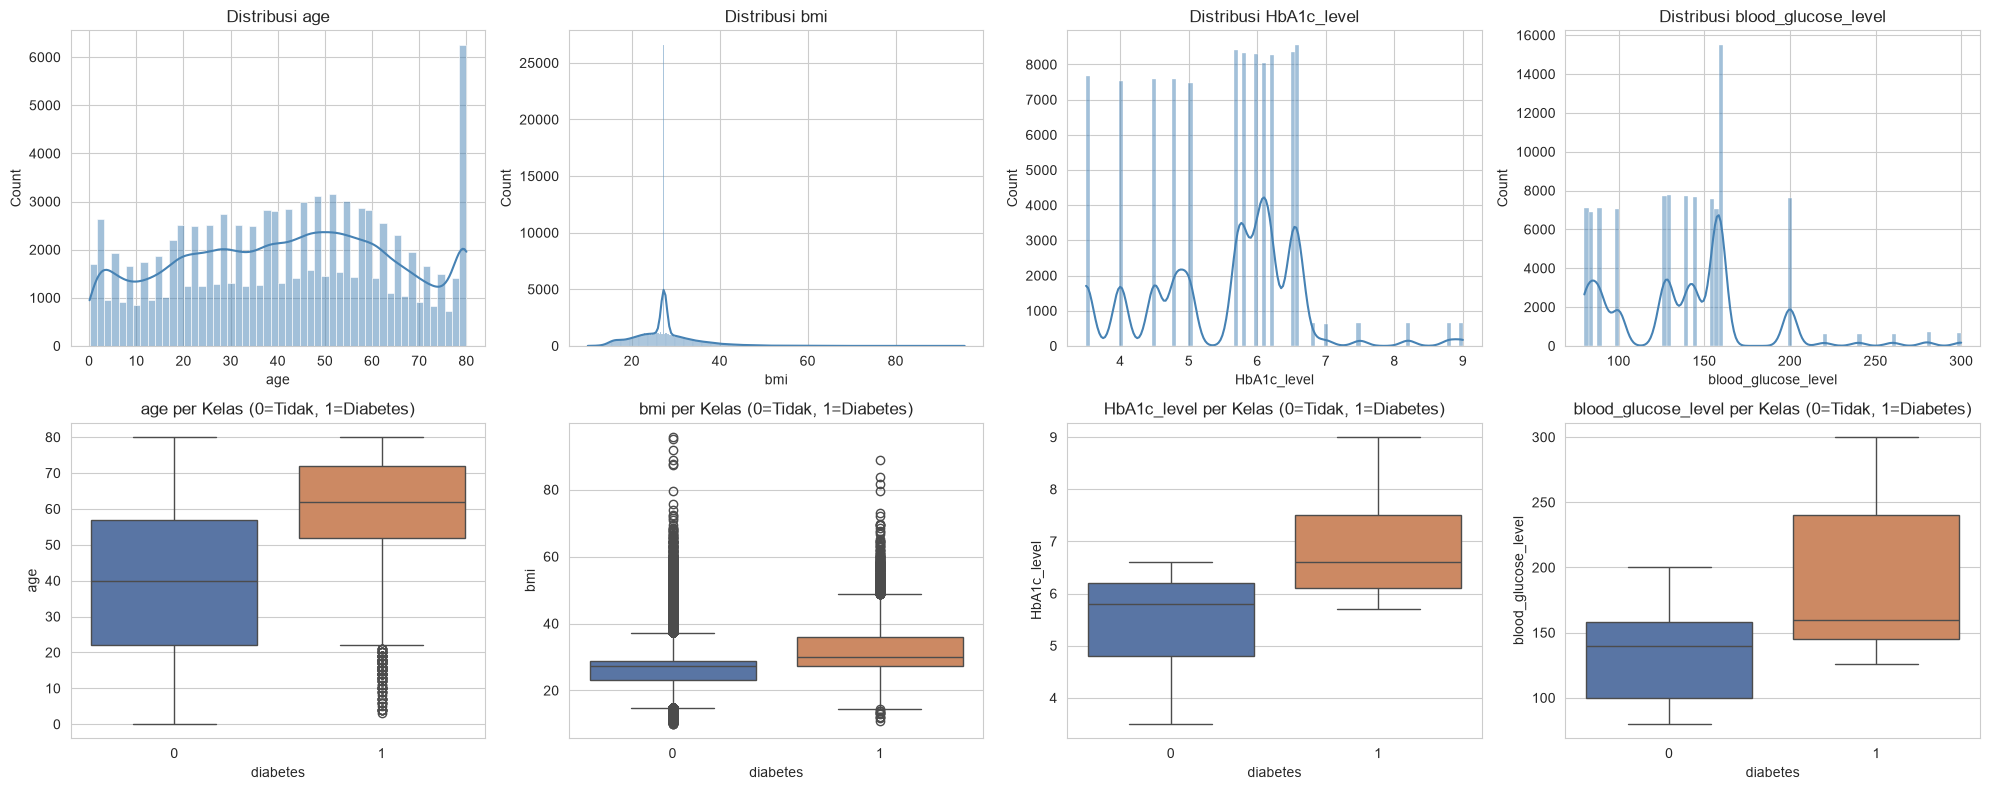

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], kde=True, ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'Distribusi {c}')
    sns.boxplot(data=df, x='diabetes', y=c, ax=axes[1, i], palette=['#4c72b0', '#dd8452'])
    axes[1, i].set_title(f'{c} per Kelas (0=Tidak, 1=Diabetes)')
plt.tight_layout(); plt.show()

### 3.3 Relasi Fitur terhadap Diabetes (Rata-rata Kelas 0 vs Kelas 1)

In [5]:
eda_cols = num_cols + ['hypertension', 'heart_disease']
rel = df.groupby('diabetes')[eda_cols].mean().T
rel.columns = ['Rata-rata Kelas 0', 'Rata-rata Kelas 1']
rel['Selisih'] = rel['Rata-rata Kelas 1'] - rel['Rata-rata Kelas 0']
rel['Δ (%)']   = rel['Selisih'] / rel['Rata-rata Kelas 0'] * 100
display(rel)

,Rata-rata Kelas 0,Rata-rata Kelas 1,Selisih,Δ (%)
age,40.1152,60.9466,20.8314,51.9290
bmi,26.8872,31.9884,5.1012,18.9727
HbA1c_level,5.3968,6.9350,1.5382,28.5021
blood_glucose_level,132.8525,194.0947,61.2422,46.0979
hypertension,0.0590,0.2456,0.1867,316.4667
heart_disease,0.0292,0.1491,0.1198,409.8648


## 4. Data Preprocessing

### 4.1 Pembersihan Data (duplikat, 'Other' pada gender, 'No Info' pada smoking_history)

In [6]:
n_awal = len(df)

# 1) Hapus baris duplikat
n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
n_setelah_dup = len(df)

# 2) Hapus gender 'Other'
n_other = (df['gender'] == 'Other').sum()
df = df[df['gender'] != 'Other']

# 3) Hapus smoking_history 'No Info'
n_noinfo = (df['smoking_history'] == 'No Info').sum()
df = df[df['smoking_history'] != 'No Info'].reset_index(drop=True)

rekap = pd.DataFrame({
    'Tahap': ['Data awal', 'Hapus duplikat', "Hapus gender 'Other'", "Hapus smoking 'No Info'", 'Data bersih'],
    'Baris dihapus': ['-', n_dup, n_other, n_noinfo, '-'],
    'Sisa baris': [n_awal, n_setelah_dup, n_setelah_dup - n_other, len(df), len(df)]
})
display(rekap)
print('Missing value  :', df.isnull().sum().sum())
print('Distribusi kelas setelah bersih:'); display(df['diabetes'].value_counts().to_frame('Jumlah').assign(**{'Persen (%)': lambda x: x['Jumlah']/x['Jumlah'].sum()*100}))

,Tahap,Baris dihapus,Sisa baris
0,Data awal,-,100000
1,Hapus duplikat,3854,96146
2,Hapus gender 'Other',18,96128
3,Hapus smoking 'No Info',32881,63247
4,Data bersih,-,63247


Missing value  : 0
Distribusi kelas setelah bersih:


,Jumlah,Persen (%)
diabetes,,
0,56210,88.8738
1,7037,11.1262


### 4.2 Encoding Fitur Kategorikal (tetap 8 fitur, tidak ada kolom baru)

In [7]:
# gender -> 0/1 ; smoking_history -> ordinal (satu kolom saja)
df['gender'] = df['gender'].map({'Female': 0, 'Male': 1})
df['smoking_history'] = df['smoking_history'].map({'never': 0, 'former': 1, 'not current': 2, 'current': 3, 'ever': 4})

X = df.drop(columns='diabetes')
y = df['diabetes']
FEATURES = list(X.columns)
print('Jumlah fitur:', len(FEATURES)); print(FEATURES)
X.head()

Jumlah fitur: 8
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,0,80.0000,0,1,0,25.1900,6.6000,140
1,1,28.0000,0,0,0,27.3200,5.7000,158
2,0,36.0000,0,0,3,23.4500,5.0000,155
3,1,76.0000,1,1,3,20.1400,4.8000,155
4,0,20.0000,0,0,0,27.3200,6.6000,85


### 4.3 Matriks Korelasi (Pearson)

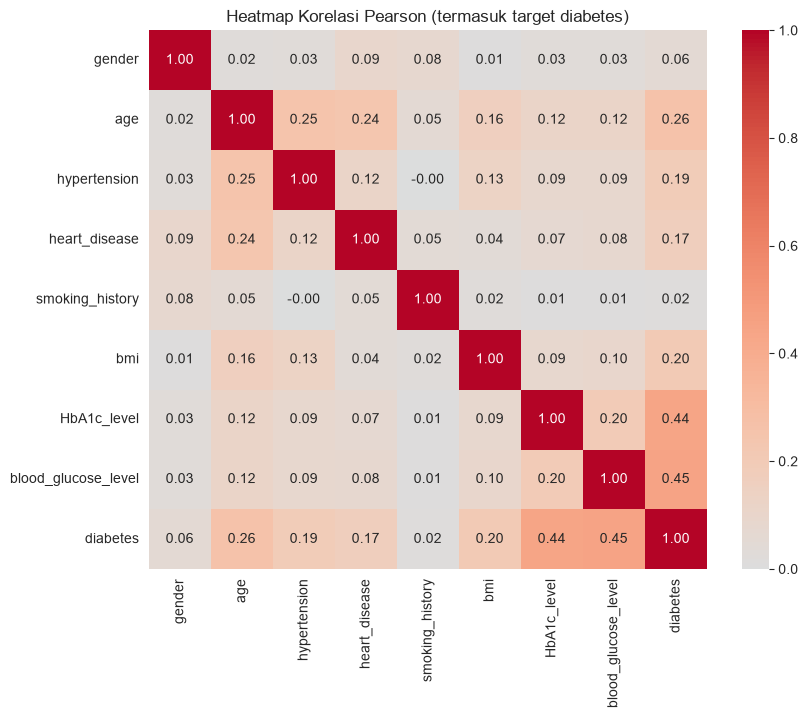

Korelasi fitur terhadap diabetes:


,Korelasi
blood_glucose_level,0.4514
HbA1c_level,0.4409
age,0.2625
bmi,0.2040
hypertension,0.1915
heart_disease,0.1690
gender,0.0565
smoking_history,0.0152


In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(method='pearson'), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Heatmap Korelasi Pearson (termasuk target diabetes)'); plt.show()

print('Korelasi fitur terhadap diabetes:')
display(df.corr()['diabetes'].drop('diabetes').sort_values(ascending=False).to_frame('Korelasi'))

## 5. Pembagian Data (Stratified Split 80:20)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

def dist(yy, nama):
    c = yy.value_counts().sort_index()
    return {'Subset': nama, 'Jumlah': len(yy), 'Kelas 0': c[0], 'Kelas 0 (%)': c[0]/len(yy)*100,
            'Kelas 1': c[1], 'Kelas 1 (%)': c[1]/len(yy)*100}

display(pd.DataFrame([dist(y_train, 'Data Latih (80%)'), dist(y_test, 'Data Uji (20%)'), dist(y, 'Total')]).set_index('Subset'))

,Jumlah,Kelas 0,Kelas 0 (%),Kelas 1,Kelas 1 (%)
Subset,,,,,
Data Latih (80%),50597,44967,88.8729,5630,11.1271
Data Uji (20%),12650,11243,88.8775,1407,11.1225
Total,63247,56210,88.8738,7037,11.1262


## 6. Penanganan Imbalanced Data (SMOTE)

,Sebelum SMOTE,Sesudah SMOTE
Kelas,,
0,44967,44967
1,5630,44967


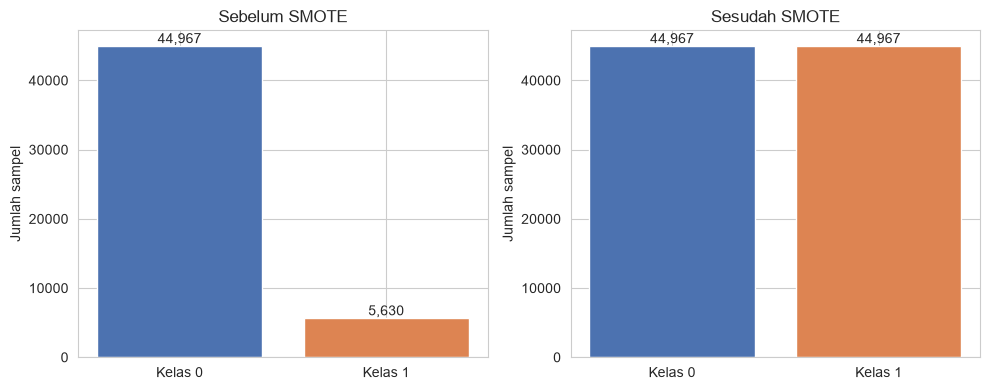

In [10]:
# SMOTE hanya diterapkan pada DATA LATIH (data uji tidak disentuh)
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

before, after = y_train.value_counts().sort_index(), y_train_sm.value_counts().sort_index()
display(pd.DataFrame({'Sebelum SMOTE': before, 'Sesudah SMOTE': after}).rename_axis('Kelas'))

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
for a, d, t in zip(ax, [before, after], ['Sebelum SMOTE', 'Sesudah SMOTE']):
    a.bar(['Kelas 0', 'Kelas 1'], d.values, color=['#4c72b0', '#dd8452'])
    for i, v in enumerate(d.values): a.text(i, v, f'{v:,}', ha='center', va='bottom')
    a.set_title(t); a.set_ylabel('Jumlah sampel')
plt.tight_layout(); plt.show()

## 7. Definisi Model & Fungsi Evaluasi

In [11]:
def get_models():
    # Parameter dibuat sederhana/default agar mudah dipahami
    return {
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
        'XGBoost':       XGBClassifier(n_estimators=100, eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1),
        'LightGBM':      LGBMClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    }

def evaluate(model, Xtr, ytr, Xte, yte):
    """Latih model lalu hitung semua metrik pada data uji."""
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    prob = model.predict_proba(Xte)[:, 1]
    tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
    div = lambda a, b: a / b if b else 0
    prec, rec = div(tp, tp + fp), div(tp, tp + fn)
    return {
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Accuracy': (tp + tn) / (tp + tn + fp + fn),
        'Precision': prec,
        'Recall': rec,
        'Specificity': div(tn, tn + fp),
        'F1-Score': div(2 * prec * rec, prec + rec),
        'NPV': div(tn, tn + fn),
        'ROC-AUC': roc_auc_score(yte, prob),
        '_prob': prob,
    }
METRICS = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1-Score', 'NPV', 'ROC-AUC']

## 8. Skenario 1 vs Skenario 2: Tanpa SMOTE vs Dengan SMOTE (semua fitur)

SKENARIO 1 — TANPA SMOTE


,Accuracy,Precision,Recall,Specificity,F1-Score,NPV,ROC-AUC
Decision Tree,0.9360,0.7004,0.7427,0.9602,0.7209,0.9676,0.8518
Random Forest,0.9615,0.9519,0.6887,0.9956,0.7992,0.9623,0.9592
XGBoost,0.9635,0.9583,0.7022,0.9962,0.8105,0.9639,0.9708
LightGBM,0.9637,0.9712,0.6944,0.9974,0.8098,0.9631,0.9728


SKENARIO 2 — DENGAN SMOTE


,Accuracy,Precision,Recall,Specificity,F1-Score,NPV,ROC-AUC
Decision Tree,0.9349,0.6914,0.7484,0.9582,0.7188,0.9682,0.8542
Random Forest,0.9456,0.7630,0.7413,0.9712,0.7520,0.9677,0.9615
XGBoost,0.9581,0.8919,0.7093,0.9892,0.7902,0.9645,0.9692
LightGBM,0.9596,0.9022,0.7143,0.9903,0.7973,0.9652,0.9706


Perubahan (Dengan SMOTE − Tanpa SMOTE):


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Decision Tree,-0.0012,-0.0090,0.0057,-0.0022,0.0024
Random Forest,-0.0159,-0.1889,0.0526,-0.0472,0.0022
XGBoost,-0.0054,-0.0664,0.0071,-0.0203,-0.0015
LightGBM,-0.0041,-0.0690,0.0199,-0.0125,-0.0022


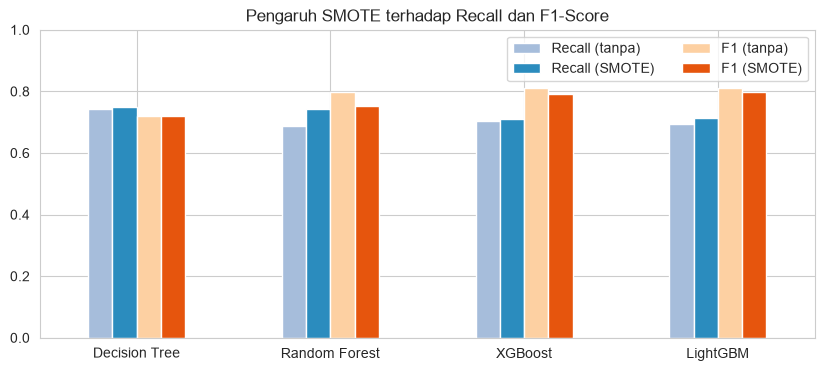

In [12]:
res_no, res_sm = {}, {}
for name in get_models():
    res_no[name] = evaluate(get_models()[name], X_train,    y_train,    X_test, y_test)   # tanpa SMOTE
    res_sm[name] = evaluate(get_models()[name], X_train_sm, y_train_sm, X_test, y_test)   # dengan SMOTE

tbl_no = pd.DataFrame(res_no).T[METRICS].astype(float)
tbl_sm = pd.DataFrame(res_sm).T[METRICS].astype(float)

print('SKENARIO 1 — TANPA SMOTE'); display(tbl_no)
print('SKENARIO 2 — DENGAN SMOTE'); display(tbl_sm)

print('Perubahan (Dengan SMOTE − Tanpa SMOTE):')
display((tbl_sm - tbl_no)[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']])

# Grafik Recall & F1
cmp = pd.DataFrame({'Recall (tanpa)': tbl_no['Recall'], 'Recall (SMOTE)': tbl_sm['Recall'],
                    'F1 (tanpa)': tbl_no['F1-Score'], 'F1 (SMOTE)': tbl_sm['F1-Score']})
cmp.plot(kind='bar', figsize=(10, 4), rot=0, color=['#a6bddb', '#2b8cbe', '#fdd0a2', '#e6550d'])
plt.title('Pengaruh SMOTE terhadap Recall dan F1-Score'); plt.ylim(0, 1); plt.legend(ncol=2); plt.show()

## 9. 10-Fold Cross-Validation (data latih)
SMOTE dimasukkan ke dalam **pipeline** sehingga hanya diterapkan pada data latih di tiap fold (menghindari kebocoran data ke fold validasi).

In [13]:
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {'Accuracy': 'accuracy', 'Precision': 'precision', 'Recall': 'recall', 'F1-Score': 'f1', 'ROC-AUC': 'roc_auc'}

rows = []
for name, m in get_models().items():
    pipe = ImbPipeline([('smote', SMOTE(random_state=RANDOM_STATE)), ('model', m)])
    cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scoring, n_jobs=1)
    row = {'Model': name}
    for k in scoring:
        s = cv[f'test_{k}']
        row[k] = f'{s.mean():.4f} ± {s.std():.4f}'
    rows.append(row)

print(f'Skor {N_FOLDS}-Fold CV (Mean ± Std. Dev.) — data latih dengan SMOTE per fold')
display(pd.DataFrame(rows).set_index('Model'))

Skor 10-Fold CV (Mean ± Std. Dev.) — data latih dengan SMOTE per fold


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Decision Tree,0.9337 ± 0.0024,0.6869 ± 0.0118,0.7437 ± 0.0147,0.7141 ± 0.0103,0.8510 ± 0.0075
Random Forest,0.9447 ± 0.0026,0.7604 ± 0.0107,0.7345 ± 0.0177,0.7471 ± 0.0131,0.9620 ± 0.0038
XGBoost,0.9587 ± 0.0022,0.8987 ± 0.0126,0.7085 ± 0.0151,0.7923 ± 0.0117,0.9725 ± 0.0016
LightGBM,0.9600 ± 0.0020,0.9099 ± 0.0120,0.7108 ± 0.0149,0.7980 ± 0.0110,0.9739 ± 0.0021


## 10. Evaluasi Model Semua Fitur (Data Uji, dengan SMOTE)

### 10.1 Confusion Matrix (TP, TN, FP, FN)

,TP,TN,FP,FN
Decision Tree,1053,10773,470,354
Random Forest,1043,10919,324,364
XGBoost,998,11122,121,409
LightGBM,1005,11134,109,402


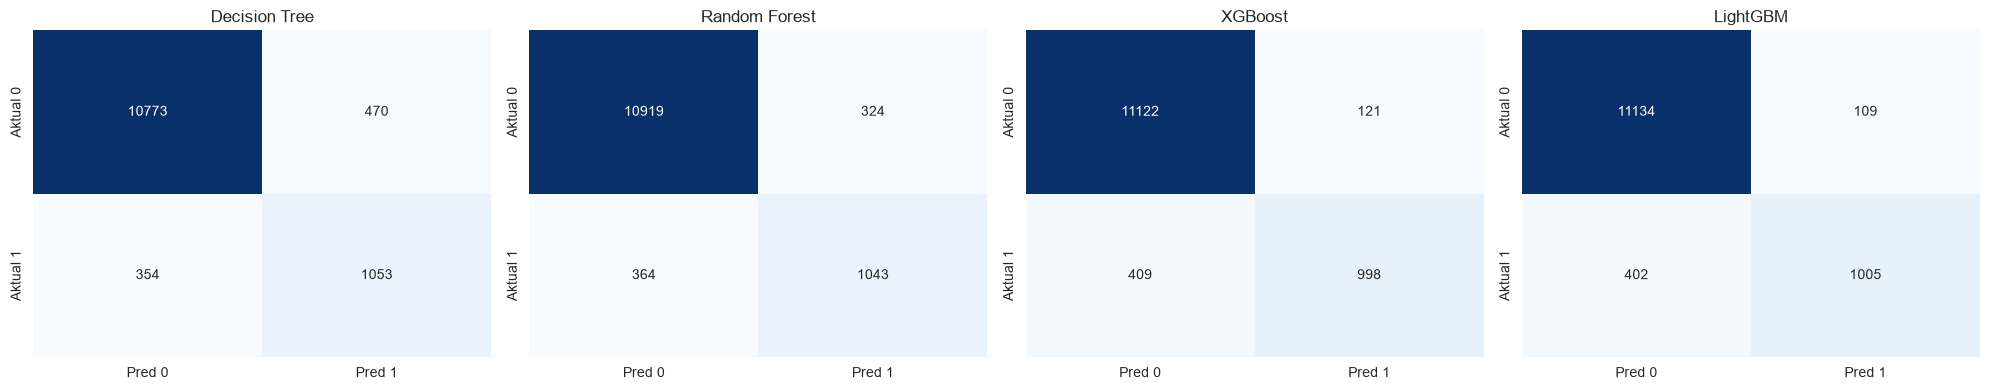

In [14]:
cm_tbl = pd.DataFrame(res_sm).T[['TP', 'TN', 'FP', 'FN']].astype(int)
display(cm_tbl)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, r) in zip(axes, res_sm.items()):
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Aktual 0', 'Aktual 1'])
    ax.set_title(name)
plt.tight_layout(); plt.show()

### 10.2 Rekapitulasi 7 Metrik Evaluasi

In [15]:
display(tbl_sm)

,Accuracy,Precision,Recall,Specificity,F1-Score,NPV,ROC-AUC
Decision Tree,0.9349,0.6914,0.7484,0.9582,0.7188,0.9682,0.8542
Random Forest,0.9456,0.7630,0.7413,0.9712,0.7520,0.9677,0.9615
XGBoost,0.9581,0.8919,0.7093,0.9892,0.7902,0.9645,0.9692
LightGBM,0.9596,0.9022,0.7143,0.9903,0.7973,0.9652,0.9706


### 10.3 Kurva ROC

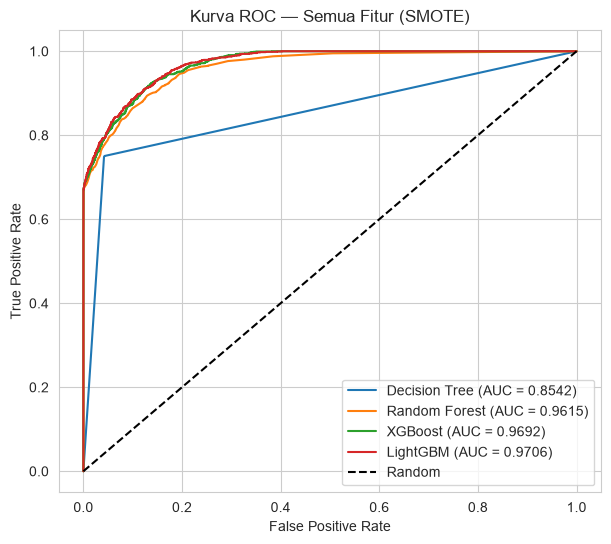

In [16]:
plt.figure(figsize=(7, 6))
for name, r in res_sm.items():
    fpr, tpr, _ = roc_curve(y_test, r['_prob'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {r['ROC-AUC']:.4f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.title('Kurva ROC — Semua Fitur (SMOTE)')
plt.legend(loc='lower right'); plt.show()

## 11. Feature Importance & Reduksi Fitur

### 11.1 Peringkat Feature Importance & Kontribusi Kumulatif

--- Decision Tree ---


,Peringkat,Importance,Kumulatif (%)
Fitur,,,
HbA1c_level,1,0.5510,55.0981
blood_glucose_level,2,0.2679,81.8917
age,3,0.1028,92.1759
bmi,4,0.0561,97.7873
smoking_history,5,0.0102,98.8049
gender,6,0.0053,99.3362
hypertension,7,0.0037,99.7021
heart_disease,8,0.0030,100.0000


--- Random Forest ---


,Peringkat,Importance,Kumulatif (%)
Fitur,,,
HbA1c_level,1,0.4114,41.1385
blood_glucose_level,2,0.2610,67.2435
age,3,0.1853,85.7760
bmi,4,0.1116,96.9356
smoking_history,5,0.0176,98.6951
gender,6,0.0066,99.3552
hypertension,7,0.0041,99.7613
heart_disease,8,0.0024,100.0000


--- XGBoost ---


,Peringkat,Importance,Kumulatif (%)
Fitur,,,
HbA1c_level,1,0.6118,61.1842
blood_glucose_level,2,0.2911,90.2942
age,3,0.0463,94.9278
bmi,4,0.0197,96.8968
gender,5,0.0087,97.7658
smoking_history,6,0.0080,98.5631
heart_disease,7,0.0078,99.3394
hypertension,8,0.0066,100.0000


--- LightGBM ---


,Peringkat,Importance,Kumulatif (%)
Fitur,,,
HbA1c_level,1,0.3550,35.5000
age,2,0.2187,57.3667
bmi,3,0.1870,76.0667
blood_glucose_level,4,0.1627,92.3333
smoking_history,5,0.0353,95.8667
gender,6,0.0177,97.6333
hypertension,7,0.0163,99.2667
heart_disease,8,0.0073,100.0000


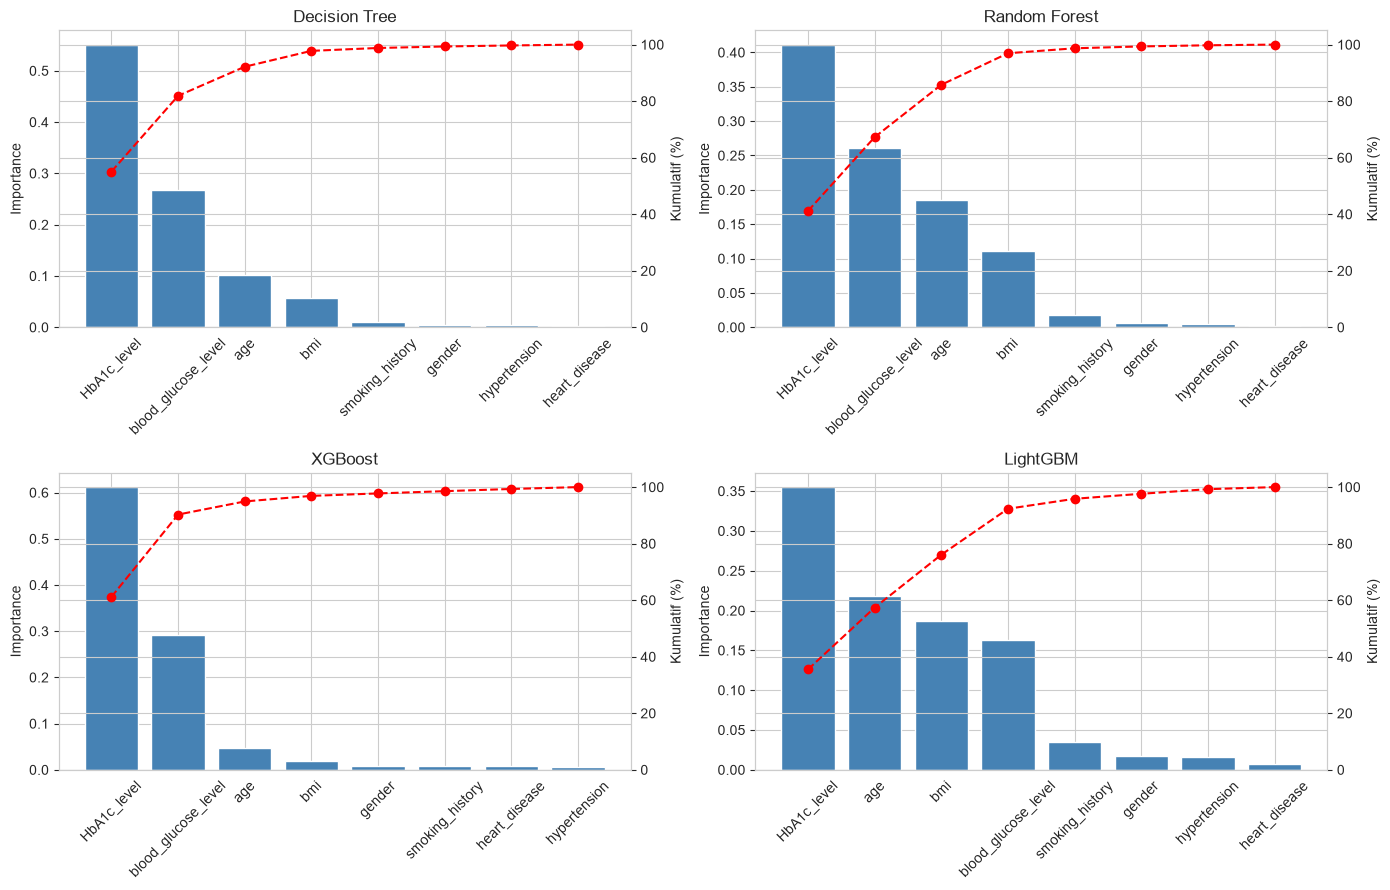

In [17]:
# Latih ulang model (data SMOTE) agar bisa mengambil feature_importances_
fitted = {}
for name, m in get_models().items():
    m.fit(X_train_sm, y_train_sm); fitted[name] = m

imp_tables = {}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (name, m) in zip(axes.ravel(), fitted.items()):
    imp = pd.Series(m.feature_importances_, index=FEATURES).astype(float)
    imp = imp / imp.sum()                              # normalisasi → total 100%
    imp = imp.sort_values(ascending=False)
    t = pd.DataFrame({'Importance': imp, 'Kumulatif (%)': imp.cumsum() * 100})
    t.index.name = 'Fitur'; t.insert(0, 'Peringkat', range(1, len(t) + 1))
    imp_tables[name] = t

    ax.bar(t.index, t['Importance'], color='steelblue'); ax.tick_params(axis='x', rotation=45)
    ax.set_ylabel('Importance'); ax.set_title(name)
    ax2 = ax.twinx(); ax2.plot(t.index, t['Kumulatif (%)'], 'r--o'); ax2.set_ylim(0, 105); ax2.set_ylabel('Kumulatif (%)')
    print(f'--- {name} ---'); display(t)
plt.tight_layout(); plt.show()

### 11.2 Semua Fitur vs Fitur Terpilih

In [18]:
print(f'Reduksi fitur: membuang {N_DROP_FEATURES} fitur terbawah dari {len(FEATURES)} fitur  (ubah N_DROP_FEATURES di bagian konfigurasi)\n')

cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
out, sel_info = [], []
for name in get_models():
    # fitur terpilih = semua fitur dikurangi N fitur dengan importance terendah (menurut model tsb)
    ranking = imp_tables[name].index.tolist()
    selected = ranking[:len(ranking) - N_DROP_FEATURES]
    dropped  = ranking[len(ranking) - N_DROP_FEATURES:]
    sel_info.append({'Model': name, 'Fitur Dibuang': ', '.join(dropped), 'Fitur Terpilih': ', '.join(selected)})

    r_sel = evaluate(get_models()[name], X_train_sm[selected], y_train_sm, X_test[selected], y_test)
    for c in cols:
        out.append({'Model': name, 'Metrik': c,
                    'Semua Fitur': res_sm[name][c], 'Fitur Terpilih': r_sel[c],
                    'Δ (Terpilih − Semua)': r_sel[c] - res_sm[name][c]})

display(pd.DataFrame(sel_info).set_index('Model'))
comp = pd.DataFrame(out).set_index(['Model', 'Metrik']).astype(float)
display(comp)

Reduksi fitur: membuang 0 fitur terbawah dari 8 fitur  (ubah N_DROP_FEATURES di bagian konfigurasi)



,Fitur Dibuang,Fitur Terpilih
Model,,
Decision Tree,,"HbA1c_level, blood_glucose_level, age, bmi, sm..."
Random Forest,,"HbA1c_level, blood_glucose_level, age, bmi, sm..."
XGBoost,,"HbA1c_level, blood_glucose_level, age, bmi, ge..."
LightGBM,,"HbA1c_level, age, bmi, blood_glucose_level, sm..."


Semua Fitur  Fitur Terpilih  Δ (Terpilih − Semua)
Model         Metrik                                                      
Decision Tree Accuracy        0.9349          0.9335               -0.0013
              Precision       0.6914          0.6852               -0.0062
              Recall          0.7484          0.7441               -0.0043
              F1-Score        0.7188          0.7135               -0.0053
              ROC-AUC         0.8542          0.8515               -0.0026
Random Forest Accuracy        0.9456          0.9466                0.0010
              Precision       0.7630          0.7691                0.0061
              Recall          0.7413          0.7434                0.0021
              F1-Score        0.7520          0.7561                0.0041
              ROC-AUC         0.9615          0.9605               -0.0009
XGBoost       Accuracy        0.9581          0.9581                0.0000
              Precision       0.8919          0.8919                0.0000
              Recall          0.7093          0.7093                0.0000
              F1-Score        0.7902          0.7902                0.0000
              ROC-AUC         0.9692          0.9692                0.0000
LightGBM      Accuracy        0.9596          0.9596                0.0000
              Precision       0.9022          0.9022                0.0000
              Recall          0.7143          0.7143                0.0000
              F1-Score        0.7973          0.7973                0.0000
              ROC-AUC         0.9706          0.9706                0.0000

## Catatan Singkat
- Evaluasi pada **data uji** selalu memakai data asli (tidak di-SMOTE).

# 12. Export Model ke .pkl

In [19]:
import os, joblib
from sklearn.metrics import roc_curve

OUT_DIR = 'artifacts'                     # folder hasil export (taruh di sebelah app.py)
MAX_DROP = len(FEATURES) - 2              # maksimal fitur yang boleh dibuang (sisa minimal 2 fitur)
os.makedirs(OUT_DIR, exist_ok=True)

grid = np.linspace(0, 1, 201)             # grid FPR agar kurva ROC ringan disimpan
results = {}                              # semua angka untuk dashboard: results[n_drop][model]

for n_drop in range(0, MAX_DROP + 1):
    models_this_n, results[n_drop] = {}, {}
    for name in get_models():
        ranking  = imp_tables[name].index.tolist()          # urutan importance (dari notebook)
        selected = ranking[:len(ranking) - n_drop]          # buang n_drop fitur terbawah
        dropped  = ranking[len(ranking) - n_drop:]

        m = get_models()[name]
        r = evaluate(m, X_train_sm[selected], y_train_sm, X_test[selected], y_test)  # fit + evaluasi
        fpr, tpr, _ = roc_curve(y_test, r['_prob'])

        models_this_n[name] = {'model': m, 'features': selected}
        results[n_drop][name] = {
            'selected': selected, 'dropped': dropped,
            'metrics': {k: float(r[k]) for k in METRICS},
            'cm': {k: int(r[k]) for k in ['TN', 'FP', 'FN', 'TP']},
            'roc': {'fpr': grid, 'tpr': np.interp(grid, fpr, tpr)},
        }
    # satu file model per jumlah fitur yang dibuang
    joblib.dump(models_this_n, f'{OUT_DIR}/models_drop_{n_drop}.pkl', compress=3)
    print(f'models_drop_{n_drop}.pkl tersimpan')

# ringkasan data untuk halaman Beranda dashboard
split_tbl = pd.DataFrame([dist(y_train, 'Data Latih (80%)'), dist(y_test, 'Data Uji (20%)'), dist(y, 'Total')])
meta = {
    'features': FEATURES, 'max_drop': MAX_DROP,
    'cleaning': rekap, 'split': split_tbl,
    'smote': pd.DataFrame({'Sebelum SMOTE': before, 'Sesudah SMOTE': after}),
    'importance': imp_tables,                              # tabel importance + kumulatif tiap model
    'feat_stats': X.describe().T[['min', 'max', 'mean']],  # rentang nilai untuk form prediksi
    'n_clean': len(X),
}

# ---- tambahan untuk halaman EDA, Preprocessing, dan Model di dashboard ----
raw = pd.read_csv(CSV_PATH)                                   # data mentah (untuk EDA)
_num = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']
_desc = raw[_num].agg(['min', 'max', 'mean', 'median', 'std']).T
_desc.columns = ['Min', 'Maks', 'Mean', 'Median', 'Std. Dev.']
def _freq(c):
    f = raw[c].value_counts().to_frame('Frekuensi'); f['Persen (%)'] = f['Frekuensi'] / len(raw) * 100
    return f.rename_axis(c)
_cols = _num + ['hypertension', 'heart_disease']
_rel = raw.groupby('diabetes')[_cols].mean().T
_rel.columns = ['Rata-rata Kelas 0', 'Rata-rata Kelas 1']
_rel['Selisih'] = _rel['Rata-rata Kelas 1'] - _rel['Rata-rata Kelas 0']
_rel['Δ (%)'] = _rel['Selisih'] / _rel['Rata-rata Kelas 0'] * 100
meta['eda'] = {
    'n_raw': len(raw), 'desc': _desc,
    'freq_gender': _freq('gender'), 'freq_smoking': _freq('smoking_history'),
    'sample': raw.sample(6000, random_state=RANDOM_STATE).reset_index(drop=True),  # sampel untuk grafik
    'rel': _rel,
    'corr': df.corr(),                                         # df = data bersih + encoding
}
meta['no_smote']   = tbl_no                                    # skenario 1 (semua fitur)
meta['with_smote'] = tbl_sm                                    # skenario 2 (semua fitur)
meta['cv'] = pd.DataFrame(rows) if 'rows' in globals() else None   # tabel 10-fold CV dari bagian 9
joblib.dump({'results': results, 'meta': meta}, f'{OUT_DIR}/results.pkl', compress=3)
print('results.pkl tersimpan. Selesai — salin folder "artifacts" ke folder dashboard.')

models_drop_0.pkl tersimpan
models_drop_1.pkl tersimpan
models_drop_2.pkl tersimpan
models_drop_3.pkl tersimpan
models_drop_4.pkl tersimpan
models_drop_5.pkl tersimpan
models_drop_6.pkl tersimpan
results.pkl tersimpan. Selesai — salin folder "artifacts" ke folder dashboard.
